# 00 · Verify the quantum environment with a Bell state

## Question

Can the local Qiskit Aer environment prepare and measure a Bell state with the expected outcomes?

## Concept

**Physics / quantum view.** A qubit is a two-level quantum system. Its statevector stores complex amplitudes for the possible basis states. An entangled state such as the Bell state has a joint state that cannot be written as a product of separate qubit states.

A qubit starts in $\lvert0\rangle$. A Hadamard gate on qubit 0 creates $(\lvert0\rangle+\lvert1\rangle)/\sqrt{2}$. A controlled-NOT then flips qubit 1 only in the branch where qubit 0 is 1, giving

$$\lvert\Phi^+\rangle=\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt{2}}.$$

Both gates are **unitary**: they preserve the state norm and are reversible. At measurement, the squared magnitude of each amplitude gives the outcome probability. The ideal circuit therefore gives $P(00)=P(11)=1/2$ and $P(01)=P(10)=0$. One **shot** is one preparation and measurement. A finite batch estimates these probabilities.

Here $\lvert\Phi^+\rangle$ labels the Bell state, $\lvert00\rangle$ and $\lvert11\rangle$ are two-qubit basis states, and $P$ denotes a dimensionless outcome probability. The experiment executes the circuit using Aer [1].

## Exercise / prediction

Before running, predict which strings can appear in 1,000 shots. Should the two nonzero counts be exactly equal? What outcomes would you expect if you removed the controlled-NOT gate?

## Worked example

Use the project virtual environment as the notebook kernel. From the repository root, install dependencies with `python -m pip install -r requirements.txt` if needed.

In [1]:
import platform

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

print("Python:", platform.python_version())
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)

shots, seed = 1000, 42
circuit = QuantumCircuit(2, 2)
circuit.h(0)
circuit.cx(0, 1)
circuit.measure([0, 1], [0, 1])
print(circuit.draw(output="text"))

backend = AerSimulator()
counts = backend.run(circuit, shots=shots, seed_simulator=seed).result().get_counts()

Python: 3.15.2
Qiskit: 2.6.2
Qiskit Aer: 0.18.4
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


## Result

Check that all shots are accounted for and that every measured string belongs to the predicted support.

Backend: aer_simulator; shots: 1000; simulator seed: 42
00: 510 shots (51.0%)
11: 490 shots (49.0%)


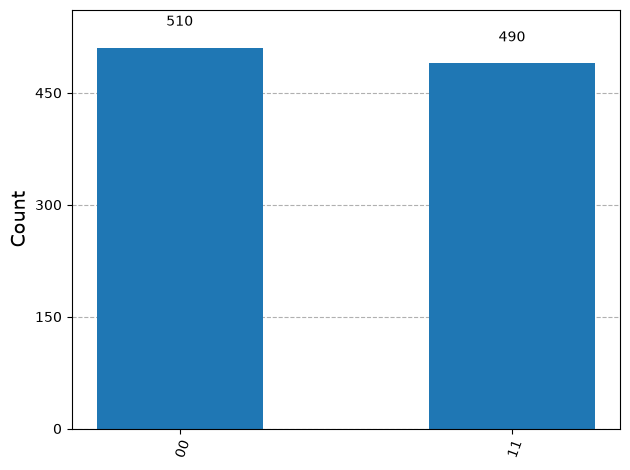

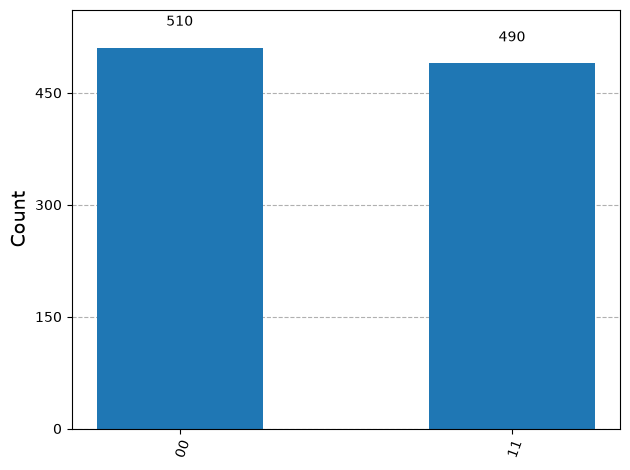

In [2]:
from qiskit.visualization import plot_histogram

assert sum(counts.values()) == shots
assert set(counts) == {"00", "11"}
print(f"Backend: {backend.name}; shots: {shots}; simulator seed: {seed}")
for bit_string, count in sorted(counts.items()):
    print(f"{bit_string}: {count} shots ({count / shots:.1%})")
plot_histogram(counts)

**Exercise check.** Counts fluctuate around 500 each. Without controlled-NOT, qubit 1 stays at 0 and qubit 0 can be 0 or 1. Qiskit displays qubit 0 on the right, so the possible strings would be 00 and 01.

## Takeaway

The Bell experiment checks that the local quantum stack can prepare a state, sample it, and reproduce the predicted outcome support. It establishes the simulator environment for the later optimization notebooks.

## Presentation asset

Place the two-gate Bell circuit next to the two-bar shot histogram. Label the ideal probability of each bar as 50%.

MkDocs topic for this notebook: `docs/simulation.md`.

## Next step

[Notebook 01](01_policy_lookup_2x2.ipynb) establishes the exact classical answer for the first policy-map problem. Later notebooks encode that problem and use Aer to sample candidate solutions.

### References

[1] Qiskit Aer, [AerSimulator](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html), version 0.18.4.